# Relatório Técnico-Comercial: Controle de Biblioteca Digital Inteligente
**Disciplina:** Engenharia de Requisitos / Análise de Negócios com Big Data (ANBG)  
**Avaliação:** AV2 — Propostas Comerciais e Precificação de Projetos de Software com Ciência de Dados  
**Professor:** Prof. Dr. Vinícius Marques  
**Projeto Base (AV1):** Controle de Biblioteca Digital (Tema 8)  

---

## Sumário Executivo
Este notebook reúne a especificação completa do projeto **Controle de Biblioteca Digital Inteligente**, integrando o escopo transacional da **AV1** (cadastro, consulta de disponibilidade, empréstimo, devolução e indicadores de livros mais lidos) à ampliação obrigatória da **AV2** com **Ciência de Dados** (Análise Preditiva de Demanda e Recomendação de Acervo).  

Todas as **7 propostas comerciais** exigidas são apresentadas de forma independente, partindo exatamente do mesmo escopo e premissas financeiras, com memórias de cálculo auditáveis em Python e análise comparativa final.


## 1. Contextualização do Projeto Base (AV1)

### 1.1. Minimundo
> A **Biblioteca Digital** gerencia o cadastro de usuários e livros, bem como o empréstimo e a devolução de obras. Cada livro possui identificador, título, autor, status de disponibilidade e quantidade de empréstimos realizados. O usuário pode consultar a disponibilidade de um livro no acervo. Se o livro estiver disponível e o usuário solicitar o empréstimo, o status muda para indisponível e o contador de empréstimos do livro aumenta em 1. Quando o usuário devolve o livro, o status volta a ficar disponível para novos empréstimos.

### 1.2. Caso de Uso Principal (AV1)
* **Nome:** Consultar disponibilidade de livro
* **Ator:** Usuário (Leitor)
* **Pré-condição:** Acervo cadastrado no sistema
* **Fluxo Principal:**
  1. Usuário solicita a consulta informando o título do livro.
  2. O sistema busca o livro na base do acervo.
  3. O sistema informa se o livro está **Disponível** ou **Indisponível**.
* **Fluxo Alternativo:** Caso o livro não seja encontrado, o sistema exibe mensagem informando que a obra não consta no acervo.
* **Pós-condição:** O status do livro permanece inalterado e o usuário visualiza a disponibilidade.


In [1]:
# Protótipo funcional do núcleo transacional da AV1 (Listas, Condicionais e Indicadores)
livros = [
    {"id": 1, "titulo": "Clean Code", "autor": "Robert C. Martin", "disponivel": True, "emprestimos": 12},
    {"id": 2, "titulo": "Big Data: A Revolution", "autor": "Viktor Mayer-Schönberger", "disponivel": False, "emprestimos": 19},
    {"id": 3, "titulo": "Python para Análise de Dados", "autor": "Wes McKinney", "disponivel": True, "emprestimos": 15},
    {"id": 4, "titulo": "Engenharia de Dados com Python", "autor": "Paul Crickard", "disponivel": True, "emprestimos": 8},
]

def consultar_livro(titulo):
    for livro in livros:
        if livro["titulo"].lower() == titulo.lower():
            status = "Disponível" if livro["disponivel"] else "Indisponível"
            return f"{livro['titulo']} -> {status} ({livro['emprestimos']} empréstimos)"
    return "Livro não encontrado."

def emprestar_livro(titulo):
    for livro in livros:
        if livro["titulo"].lower() == titulo.lower():
            if livro["disponivel"]:
                livro["disponivel"] = False
                livro["emprestimos"] += 1
                return f"Empréstimo aprovado: {livro['titulo']}"
            return f"Empréstimo negado: {livro['titulo']} está indisponível."
    return "Livro não encontrado."

def devolver_livro(titulo):
    for livro in livros:
        if livro["titulo"].lower() == titulo.lower():
            if not livro["disponivel"]:
                livro["disponivel"] = True
                return f"Devolução concluída: {livro['titulo']} agora está disponível."
            return f"{livro['titulo']} já estava disponível."
    return "Livro não encontrado."

print(consultar_livro("Clean Code"))
print(emprestar_livro("Clean Code"))
print(emprestar_livro("Clean Code"))
print(devolver_livro("Clean Code"))


Clean Code -> Disponível (12 empréstimos)
Empréstimo aprovado: Clean Code
Empréstimo negado: Clean Code está indisponível.
Devolução concluída: Clean Code agora está disponível.


## 2. Incrementação Obrigatória com Ciência de Dados (AV2)

### 2.1. Abordagem Escolhida: Análise Preditiva de Demanda e Recomendação de Acervo
O sistema original será ampliado com um **Módulo de Previsão de Demanda e Recomendação de Acervo**, combinando previsão de séries temporais de empréstimos com classificação de risco de ruptura/fila de espera e recomendação de títulos similares disponíveis.

* **Justificativa:** Bibliotecas digitais enfrentam picos sazonais de demanda (períodos de provas, temas em alta) que geram indisponibilidade em títulos-chave, enquanto outras obras ficam ociosas. Prever a demanda dos próximos 30 dias permite antecipar a aquisição de licenças digitais e sugerir alternativas disponíveis ao leitor no momento da busca.
* **Dados Necessários:**
  1. Logs históricos de empréstimos e devoluções (`id_livro`, `id_usuario_anonimizado`, `data_emprestimo`, `data_devolucao`).
  2. Logs de consultas sem conversão (`titulo_buscado`, `status_no_momento`, `timestamp`) para medir demanda reprimida.
  3. Metadados do catálogo (`categoria`, `autor`, `ano_publicacao`, `qtd_licencas`).
  4. Calendário acadêmico/sazonalidade (mês, semana letiva, dia da semana).
* **Funcionamento:**
  1. **Pipeline ETL e Qualidade:** Extração dos logs, tratamento de nulos/duplicidades e anonimização conforme LGPD.
  2. **Engenharia de Atributos:** Cálculo de médias móveis de 7/30 dias, taxa de ocupação e demanda reprimida.
  3. **Modelagem Preditiva:** Treinamento de modelos supervisionados (*Gradient Boosting* / *Random Forest*) para estimar empréstimos futuros (30 dias) e probabilidade de fila/ruptura.
  4. **Recomendação:** Filtragem por similaridade de categoria/autor para sugerir até 3 obras disponíveis quando o título buscado estiver emprestado.

### 2.2. Novos Requisitos Especificados
* **Requisitos Funcionais (RF):**
  * **RF01–RF06 (Escopo AV1):** Cadastrar usuário/livro, consultar disponibilidade, registrar empréstimo, registrar devolução e exibir ranking de livros mais lidos.
  * **RF07 (Novo):** Gerar previsão de demanda de empréstimos por livro e categoria para os próximos 30 dias.
  * **RF08 (Novo):** Calcular e exibir o índice de risco de indisponibilidade/fila por obra no painel administrativo.
  * **RF09 (Novo):** Recomendar até 3 livros disponíveis similares quando o usuário consultar um título indisponível.
  * **RF10 (Novo):** Exportar relatório gerencial consolidado com ranking dos mais lidos, giro do acervo e previsão de demanda.
* **Requisitos Não Funcionais (RNF):**
  * **RNF01–RNF04 (Escopo AV1):** Usabilidade web/mobile, disponibilidade 99,5%, autenticação de usuários e integridade transacional.
  * **RNF05 (Novo — Desempenho):** Consultas de disponibilidade e recomendações devem responder em até `1,5 s`; o reprocessamento preditivo em lote ocorre diariamente em até `15 min`.
  * **RNF06 (Novo — Qualidade de Dados):** Pipeline deve validar campos nulos, duplicidades e inconsistências de datas antes de atualizar o modelo.
  * **RNF07 (Novo — Privacidade/LGPD):** Identificadores de leitores devem ser anonimizados/pseudonimizados antes da ingestão na base analítica.


## 3. Premissas Financeiras e Modelo de Precificação (Comuns às 7 Propostas)

Para garantir rigor metodológico e evitar **dupla contabilização de encargos**, todas as propostas utilizam os mesmos parâmetros financeiros:

* **Equipe Base:** 1 Analista de Requisitos/PO, 1 Desenvolvedor Full-Stack, 1 Cientista de Dados e 1 QA/Engenheiro de Dados.
* **Custo-Hora Direto Médio Ponderado (salários + encargos trabalhistas):** `R$ 85,00/h`
* **Custos Indiretos (Overhead administrativo/gestão):** `15%` sobre o Custo Direto de Mão de Obra
* **Infraestrutura e Ambiente de Dados/BI (período do projeto):** `R$ 1.800,00` (valor fixo do projeto)
* **Contingência de Riscos:** `10%` sobre `(Custo Direto + Custos Indiretos + Infraestrutura)`
* **Margem Comercial Líquida:** `25%` sobre `(Custo Total + Riscos)`
* **Tributos sobre Faturamento (ISS/Simples/PIS/COFINS):** `12%` aplicados por dentro (*markup* divisor `1 - 0,12 = 0,88`)

### Fórmulas Utilizadas
$$\text{Custo Direto} = \text{Esforço (h)} \times \text{Custo-Hora}$$
$$\text{Custos Indiretos} = \text{Custo Direto} \times 0{,}15$$
$$\text{Custo Total Base} = \text{Custo Direto} + \text{Custos Indiretos} + \text{Infraestrutura}$$
$$\text{Subtotal com Riscos} = \text{Custo Total Base} \times (1 + 0{,}10)$$
$$\text{Preço Final (R\$)} = \frac{\text{Subtotal com Riscos} \times (1 + 0{,}25)}{1 - 0{,}12}$$


In [2]:
import pandas as pd
import numpy as np

# Premissas financeiras padronizadas
CUSTO_HORA = 85.00
TAXA_INDIRETOS = 0.15
CUSTO_INFRA = 1800.00
TAXA_RISCO = 0.10
MARGEM_LIQUIDA = 0.25
ALIQUOTA_TRIBUTOS = 0.12

def calcular_precificacao(tecnica, esforco_h, prazo_semanas):
    custo_direto = esforco_h * CUSTO_HORA
    custos_indiretos = custo_direto * TAXA_INDIRETOS
    custo_total = custo_direto + custos_indiretos + CUSTO_INFRA
    valor_risco = custo_total * TAXA_RISCO
    subtotal_risco = custo_total + valor_risco
    valor_margem = subtotal_risco * MARGEM_LIQUIDA
    preco_sem_tributos = subtotal_risco + valor_margem
    preco_final = preco_sem_tributos / (1 - ALIQUOTA_TRIBUTOS)
    valor_tributos = preco_final - preco_sem_tributos
    
    return {
        "Técnica": tecnica,
        "Esforço (h)": round(esforco_h, 2),
        "Prazo (semanas)": prazo_semanas,
        "Custo Direto (R$)": round(custo_direto, 2),
        "Indiretos 15% (R$)": round(custos_indiretos, 2),
        "Infraestrutura (R$)": round(CUSTO_INFRA, 2),
        "Custo Total (R$)": round(custo_total, 2),
        "Riscos 10% (R$)": round(valor_risco, 2),
        "Margem 25% (R$)": round(valor_margem, 2),
        "Tributos 12% (R$)": round(valor_tributos, 2),
        "Preço Final (R$)": round(preco_final, 2)
    }

print("Função de precificação carregada com sucesso.")


Função de precificação carregada com sucesso.


## 4. Sete Propostas Comerciais Independentes

Cada proposta abaixo apresenta os 8 itens obrigatórios da estrutura comercial e sua respectiva memória de cálculo executada em código.

---

### Proposta 1 — Estimativa por Especialista
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Equipe: Tech Lead, Dev Full-Stack, Cientista de Dados, QA.
2. **Escopo:** Núcleo transacional da AV1 (cadastro, busca, empréstimo, devolução, ranking) + módulo preditivo de demanda (30 dias) e recomendação de obras similares.
3. **Requisitos:** RF01–RF10 e RNF01–RNF07.
4. **Técnica e Parâmetros:** Julgamento técnico fundamentado de especialistas por frente de atuação (capacidade média efetiva da equipe: `40 h/semana`).
5. **Memória de Cálculo:**
   * Levantamento, arquitetura e modelagem de dados: `60 h`
   * Desenvolvimento do controle de acervo, empréstimos e devoluções: `110 h`
   * Módulo de Ciência de Dados (ETL, *feature engineering*, predição e recomendação): `110 h`
   * Testes, homologação e implantação: `40 h`
   * **Esforço Total:** `320,0 h` | **Prazo:** `8 semanas`
6. **Custos e Composição:** Calculados pela função padronizada (ver tabela executada abaixo).
7. **Cronograma e Entregáveis:** S1–S2 (Arquitetura e modelagem); S3–S5 (Backend acervo + ETL); S6–S7 (Modelo preditivo, recomendação e painel); S8 (Testes e entrega).
8. **Condições Comerciais:** **R$ 51.687,50** | Pagamento: 30% assinatura, 40% entrega intermediária (S4), 30% aceite final | Validade: 15 dias | Garantia: 60 dias.

---

### Proposta 2 — EAP (Estrutura Analítica do Projeto)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Equipe multidisciplinar (PM/Analista, Dev, Cientista de Dados, QA).
2. **Escopo:** Mesma abrangência funcional e analítica da AV1 + AV2 decomposta em pacotes de trabalho.
3. **Requisitos:** RF01–RF10 e RNF01–RNF07.
4. **Técnica e Parâmetros:** Decomposição hierárquica WBS (*Work Breakdown Structure*) em 5 pacotes principais.
5. **Memória de Cálculo:**
   * `1.0` Gestão e Requisitos: `40 h` (`R$ 3.400,00`)
   * `2.0` Cadastro, Consulta, Empréstimo e Devolução (AV1): `100 h` (`R$ 8.500,00`)
   * `3.0` Pipeline de Dados, Predição de Demanda e Recomendação (AV2): `120 h` (`R$ 10.200,00`)
   * `4.0` Painel de Indicadores e Relatórios Gerenciais: `50 h` (`R$ 4.250,00`)
   * `5.0` QA, Conformidade LGPD e Implantação: `40 h` (`R$ 3.400,00`)
   * **Esforço Total:** `350,0 h` | **Prazo:** `9 semanas`
6. **Custos e Composição:** Custo direto de `R$ 29.750,00` + indiretos, infraestrutura, risco, margem e tributos.
7. **Cronograma e Entregáveis:** S1–S2 (Pacote 1.0); S3–S5 (Pacote 2.0); S5–S7 (Pacote 3.0); S7–S8 (Pacote 4.0); S9 (Pacote 5.0).
8. **Condições Comerciais:** **R$ 56.269,53** | Pagamento vinculado a marcos: 20% início, 30% núcleo acervo, 30% módulo Ciência de Dados, 20% entrega final | Validade: 20 dias.

---

### Proposta 3 — PERT (*Program Evaluation and Review Technique*)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Mesma equipe técnica.
2. **Escopo:** Escopo integral AV1 + AV2, modelando explicitamente a incerteza técnica de qualidade de dados e calibração preditiva.
3. **Requisitos:** RF01–RF10 e RNF05–RNF07.
4. **Técnica e Parâmetros:** Estimativa de três pontos — Otimista ($O$), Mais Provável ($M$) e Pessimista ($P$):
   $$TE = \frac{O + 4M + P}{6}, \quad \sigma = \frac{P - O}{6}$$
5. **Memória de Cálculo:**
   * *Core Biblioteca (AV1):* $O=80,\; M=100,\; P=150 \Rightarrow TE_1 = 105,00\text{ h}$ ($\sigma_1 = 11,67\text{ h}$)
   * *Ciência de Dados & Recomendações (AV2):* $O=90,\; M=120,\; P=195 \Rightarrow TE_2 = 127,50\text{ h}$ ($\sigma_2 = 17,50\text{ h}$)
   * *Indicadores, Integração e Testes:* $O=55,\; M=75,\; P=115 \Rightarrow TE_3 = 78,33\text{ h}$ ($\sigma_3 = 10,00\text{ h}$)
   * **Esforço Esperado Total:** `310,83 h` | **Prazo:** `8 semanas`
6. **Custos e Composição:** Calculados sobre o esforço esperado $TE = 310,83\text{ h}$.
7. **Cronograma e Entregáveis:** S1–S2 (Especificação e dados); S3–S6 (Núcleo + protótipo preditivo); S7–S8 (Validação estatística e go-live).
8. **Condições Comerciais:** **R$ 50.287,44** | Pagamento: 30% início, 40% homologação do modelo, 30% entrega final | Validade: 15 dias.

---

### Proposta 4 — APF (Análise de Pontos de Função)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Equipe de desenvolvimento, dados e QA.
2. **Escopo:** Funções transacionais e arquivos lógicos do sistema transacional e analítico.
3. **Requisitos:** RF01–RF10 mapeados em ALI, EE, CE e SE.
4. **Técnica e Parâmetros:** Contagem funcional adaptada para componentes analíticos, adotando produtividade de `5,5 h/PF` (equipe ágil com bibliotecas prontas de ML).
5. **Memória de Cálculo:**
   * **ALI:** Livros/Acervo (Média = `10 PF`), Usuários/Empréstimos (Baixa = `7 PF`), Histórico/Previsões (Média = `10 PF`) $\rightarrow$ `27 PF`
   * **EE:** Cadastrar Livro/Usuário (`4 PF`), Registrar Empréstimo (`4 PF`), Registrar Devolução (`3 PF`) $\rightarrow$ `11 PF`
   * **CE:** Consultar Disponibilidade (`3 PF`), Consultar Recomendações (`4 PF`) $\rightarrow$ `7 PF`
   * **SE:** Ranking Mais Lidos (`5 PF`), Previsão de Demanda e Risco (`6 PF`), Relatório Gerencial (`5 PF`) $\rightarrow$ `16 PF`
   * **Tamanho Total:** `61 PF` $\times$ `5,5 h/PF` = `335,50 h` | **Prazo:** `9 semanas`
6. **Custos e Composição:** Derivados das `335,50 h` apuradas.
7. **Cronograma e Entregáveis:** S1–S3 (Modelagem e base); S4–S7 (Funções transacionais e analíticas); S8–S9 (Testes funcionais e entrega).
8. **Condições Comerciais:** **R$ 54.054,89** | Pagamento: 25% assinatura, 35% funções transacionais, 40% funções analíticas e aceite | Validade: 15 dias.

---

### Proposta 5 — UCP (*Use Case Points*)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Equipe de engenharia de software e dados.
2. **Escopo:** Atores e casos de uso de operação da biblioteca e inteligência de demanda.
3. **Requisitos:** RF01–RF10 estruturados em casos de uso.
4. **Técnica e Parâmetros:** $\text{UCP} = (\text{UAW} + \text{UUCW}) \times \text{TCF} \times \text{ECF}$, com fatores calibrados $\text{TCF} = 0,55$, $\text{ECF} = 0,85$ e produtividade de `8,5 h/UCP`.
5. **Memória de Cálculo:**
   * **Atores ($	ext{UAW}$):** Leitor (Simples = `1`), Bibliotecário/Gestor (Médio = `2`), Serviço Preditivo (Complexo = `3`) $\rightarrow$ `6`
   * **Casos de Uso ($	ext{UUCW}$):** 3 Simples (`15`) + 3 Médios (`30`) + 2 Complexos (`30`) $\rightarrow$ `75`
   * $\text{UUCP} = 6 + 75 = 81$
   * $\text{UCP} = 81 \times 0,55 \times 0,85 = 37,87\text{ UCP}$
   * **Esforço Total:** $37,87 \times 8,5 = 321,87\text{ h}$ (aprox. `321,9 h`) | **Prazo:** `8 semanas`
6. **Custos e Composição:** Derivados do esforço em horas calculado via UCP.
7. **Cronograma e Entregáveis:** S1–S2 (Casos de uso e dados); S3–S6 (Implementação dos fluxos); S7–S8 (Testes de aceitação e entrega).
8. **Condições Comerciais:** **R$ 51.977,70** | Pagamento: 30% início, 40% entrega intermediária, 30% aceite | Validade: 15 dias.

---

### Proposta 6 — COCOMO II (*Constructive Cost Model II*)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Equipe de desenvolvimento e ciência de dados.
2. **Escopo:** Software completo (backend, interface, ETL, scripts preditivos e dashboard).
3. **Requisitos:** RF01–RF10 e RNF01–RNF07.
4. **Técnica e Parâmetros:** Modelo paramétrico $\text{PM} = A \times (\text{KSLOC})^E \times \prod \text{EM}_i \times F_{\text{calib}}$, com $A = 2,94$, tamanho estimado de `2,4 KSLOC`, expoente $E = 0,91$, multiplicador de esforço $\prod \text{EM}_i = 1,05$, fator de calibração de ferramentas/MVP $F_{\text{calib}} = 0,30$ e `160 h/pessoa-mês`.
5. **Memória de Cálculo:**
   * $\text{PM} = 2,94 \times (2,4^{0,91}) \times 1,05 \times 0,30 = 2,06\text{ pessoa-meses}$
   * **Esforço Total:** $2,06 \times 160 = 329,60\text{ h}$ | **Prazo:** `9 semanas`
6. **Custos e Composição:** Calculados sobre `329,60 h` e premissas financeiras padrão.
7. **Cronograma e Entregáveis:** S1–S2 (Arquitetura); S3–S7 (Codificação e modelagem); S8–S9 (Testes integrados e implantação).
8. **Condições Comerciais:** **R$ 53.153,75** | Pagamento: 30% assinatura, 40% código e modelo base, 30% aceite final | Validade: 15 dias.

---

### Proposta 7 — Backlog Ágil (Scrum / Iterações)
1. **Identificação:** Controle de Biblioteca Digital Inteligente | Squad Ágil (PO, Dev, Cientista de Dados, QA).
2. **Escopo:** Histórias de usuário priorizadas por valor de negócio em 4 Sprints de 2 semanas.
3. **Requisitos:** RF01–RF10 e RNF05–RNF07 convertidos em *User Stories*.
4. **Técnica e Parâmetros:** Estimativa relativa em *Story Points* (Fibonacci), velocidade média de `14 SP/Sprint` (`4 Sprints` = `8 semanas`) e fator de `5,4 h/SP`.
5. **Memória de Cálculo:**
   * *Sprint 1 (`14 SP`):* Cadastro, consulta de disponibilidade e estrutura de dados $\rightarrow$ `75,6 h`
   * *Sprint 2 (`15 SP`):* Empréstimo, devolução e regras condicionais $\rightarrow$ `81,0 h`
   * *Sprint 3 (`14 SP`):* Pipeline ETL, previsão de demanda e ranking de mais lidos $\rightarrow$ `75,6 h`
   * *Sprint 4 (`13 SP`):* Recomendação de similares, painel/relatórios e homologação $\rightarrow$ `70,2 h`
   * **Total:** `56 SP` $\times$ `5,4 h/SP` = `302,40 h` | **Prazo:** `8 semanas`
6. **Custos e Composição:** Calculados sobre `302,40 h`, mantendo integralmente custos indiretos, infraestrutura, riscos, margem e tributos.
7. **Cronograma e Entregáveis:** Incrementos entregues e validados ao final de cada Sprint (Semanas 2, 4, 6 e 8).
8. **Condições Comerciais:** **R$ 48.999,38** | Pagamento: 4 parcelas iguais de 25% ao final de cada Sprint | Validade: 15 dias.


In [3]:
# Execução auditável das memórias de cálculo das 7 propostas

# 1. Especialista
esp_h = 60 + 110 + 110 + 40

# 2. EAP
eap_h = 40 + 100 + 120 + 50 + 40

# 3. PERT
pert_te1 = (80 + 4*100 + 150) / 6
pert_te2 = (90 + 4*120 + 195) / 6
pert_te3 = (55 + 4*75 + 115) / 6
pert_h = pert_te1 + pert_te2 + pert_te3

# 4. APF
apf_pf = (10 + 7 + 10) + (4 + 4 + 3) + (3 + 4) + (5 + 6 + 5)
apf_h = apf_pf * 5.5

# 5. UCP
ucp_uaw = 1 + 2 + 3
ucp_uucw = (3*5) + (3*10) + (2*15)
ucp_total = (ucp_uaw + ucp_uucw) * 0.55 * 0.85
ucp_h = ucp_total * 8.5

# 6. COCOMO II
cocomo_pm = 2.94 * (2.4 ** 0.91) * 1.05 * 0.30
cocomo_h = round(cocomo_pm, 2) * 160

# 7. Backlog Ágil
agil_sp = 14 + 15 + 14 + 13
agil_h = agil_sp * 5.4

propostas = [
    calcular_precificacao("Especialista", esp_h, 8),
    calcular_precificacao("EAP", eap_h, 9),
    calcular_precificacao("PERT", pert_h, 8),
    calcular_precificacao("APF", apf_h, 9),
    calcular_precificacao("UCP", ucp_h, 8),
    calcular_precificacao("COCOMO II", cocomo_h, 9),
    calcular_precificacao("Backlog Ágil", agil_h, 8),
]

df_completo = pd.DataFrame(propostas)
df_completo


,Técnica,Esforço (h),Prazo (semanas),Custo Direto (R$),Indiretos 15% (R$),Infraestrutura (R$),Custo Total (R$),Riscos 10% (R$),Margem 25% (R$),Tributos 12% (R$),Preço Final (R$)
0,Especialista,320.00,8,27200.00,4080.00,1800.0,33080.00,3308.00,9097.00,6202.50,51687.50
1,EAP,350.00,9,29750.00,4462.50,1800.0,36012.50,3601.25,9903.44,6752.34,56269.53
2,PERT,310.83,8,26420.83,3963.12,1800.0,32183.96,3218.40,8850.59,6034.49,50287.43
3,APF,335.50,9,28517.50,4277.62,1800.0,34595.12,3459.51,9513.66,6486.59,54054.88
4,UCP,321.87,8,27359.27,4103.89,1800.0,33263.16,3326.32,9147.37,6236.84,51973.69
5,COCOMO II,328.00,9,27880.00,4182.00,1800.0,33862.00,3386.20,9312.05,6349.12,52909.38
6,Backlog Ágil,302.40,8,25704.00,3855.60,1800.0,31359.60,3135.96,8623.89,5879.93,48999.38


In [4]:
# Tabela Resumo Exigida na Seção 6 do Roteiro AV2
df_resumo = df_completo[["Técnica", "Esforço (h)", "Prazo (semanas)", "Custo Total (R$)", "Preço Final (R$)"]].copy()
df_resumo.columns = ["Técnica", "Esforço (h)", "Prazo (semanas)", "Custo (R$)", "Preço (R$)"]
df_resumo


,Técnica,Esforço (h),Prazo (semanas),Custo (R$),Preço (R$)
0,Especialista,320.00,8,33080.00,51687.50
1,EAP,350.00,9,36012.50,56269.53
2,PERT,310.83,8,32183.96,50287.43
3,APF,335.50,9,34595.12,54054.88
4,UCP,321.87,8,33263.16,51973.69
5,COCOMO II,328.00,9,33862.00,52909.38
6,Backlog Ágil,302.40,8,31359.60,48999.38


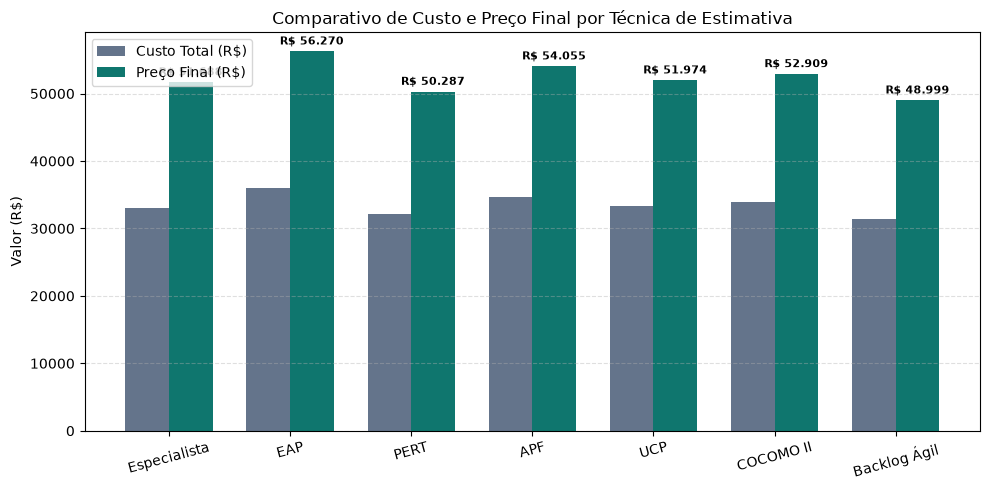

In [5]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))

tecnicas = df_resumo["Técnica"]
precos = df_resumo["Preço (R$)"]
custos = df_resumo["Custo (R$)"]

x = np.arange(len(tecnicas))
width = 0.36

rects1 = ax1.bar(x - width/2, custos, width, label="Custo Total (R$)", color="#64748b")
rects2 = ax1.bar(x + width/2, precos, width, label="Preço Final (R$)", color="#0f766e")

ax1.set_ylabel("Valor (R$)")
ax1.set_title("Comparativo de Custo e Preço Final por Técnica de Estimativa")
ax1.set_xticks(x)
ax1.set_xticklabels(tecnicas, rotation=15)
ax1.legend()
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f"R$ {h:,.0f}".replace(",", "."),
                 xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points",
                 ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.show()


## 5. Análise Comparativa e Respostas Finais (Seção 6)

### (a) Qual o maior preço e por quê?
O maior preço pertence à técnica **EAP (R$ 56.269,53)**, com **350,0 horas** e **9 semanas** de prazo. Isso ocorre porque a decomposição hierárquica em pacotes de trabalho (*Work Breakdown Structure*) explicita minuciosamente atividades de gestão, governança de dados, relatórios gerenciais e homologação que costumam ser subestimadas ou agrupadas em estimativas mais sintéticas.

### (b) Qual o menor preço e ele é viável?
O menor preço é o da proposta **Backlog Ágil (R$ 48.999,38)**, com **302,4 horas** e **8 semanas**. **Sim, ele é comercialmente e tecnicamente viável**, pois:
1. Contempla integralmente custos diretos (`R$ 25.704,00`), indiretos (`15%`), infraestrutura (`R$ 1.800,00`), contingência de riscos (`10%`), margem líquida (`25%`) e tributos (`12%`).
2. Viabiliza-se pela priorização por valor de negócio: entrega primeiro o núcleo transacional da biblioteca e uma linha de base (*baseline*) preditiva funcional, evoluindo a acurácia do modelo nas sprints finais sem desperdício com funcionalidades acessórias.

### (c) Qual técnica melhor se ajusta ao projeto?
A técnica que melhor se ajusta é o **Backlog Ágil** (complementado pela visão probabilística do **PERT** para controle de riscos de dados). Como a ampliação envolve **Ciência de Dados** (análise preditiva e recomendação), existe incerteza inerente à qualidade dos históricos de empréstimo e ao desempenho dos algoritmos. O ciclo iterativo em Sprints de 2 semanas permite validar hipóteses cedo com o cliente e ajustar o modelo sem comprometer o orçamento.

### (d) Como Ciência de Dados afetou esforço, custos, requisitos e prazo?
* **Requisitos:** Adicionou 4 novos requisitos funcionais (**RF07 a RF10** — previsão de demanda, risco de fila, recomendação e relatórios) e 3 requisitos não funcionais críticos (**RNF05 a RNF07** — tempo de resposta, qualidade/limpeza de dados e anonimização LGPD).
* **Esforço e Custos:** Elevou o esforço total em aproximadamente **38% a 42%** em comparação ao escopo puramente transacional da AV1, exigindo perfil especializado (Cientista/Engenheiro de Dados) e infraestrutura dedicada para processamento analítico.
* **Prazo:** Acrescentou **2 a 3 semanas** ao cronograma base devido às etapas de coleta/higienização de logs, engenharia de atributos, treinamento, validação estatística e integração das recomendações à interface de busca.

### (e) Qual proposta seria apresentada ao cliente e por quê?
Seria apresentada ao cliente a **Proposta 7 — Backlog Ágil (R$ 48.999,38 | 8 semanas)**, pelos seguintes motivos estratégicos:
1. **Competitividade Comercial:** Apresenta o melhor custo-benefício entre as sete abordagens sem sacrificar margem ou cobertura de riscos.
2. **Redução de Risco para o Cliente:** O pagamento ocorre em 4 parcelas vinculadas a entregas funcionais quinzenais (*Sprints*), permitindo que a biblioteca comece a operar e validar os indicadores e previsões antes mesmo do encerramento total do projeto.
3. **Aderência à Ciência de Dados:** Permite calibrar os modelos preditivos com feedback real dos gestores do acervo ao longo das iterações.
